## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

In [53]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
  np.random.seed(100)

  X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
  X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
  X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])

  gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
  gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
  gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
  df = pd.concat([gdf1,gdf2,gdf3],axis=0)
  return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

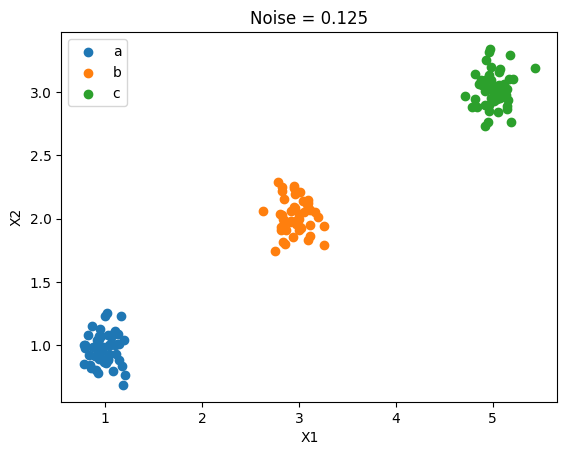

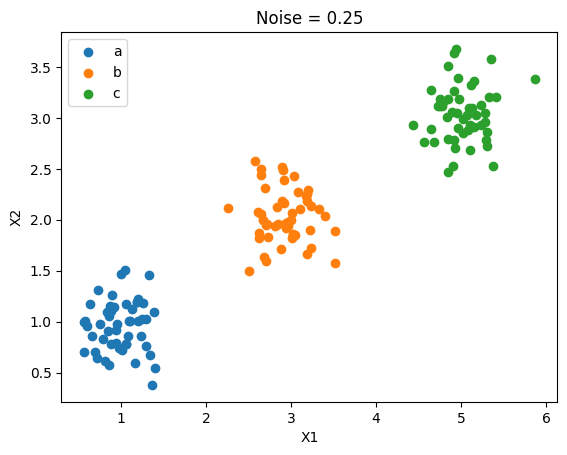

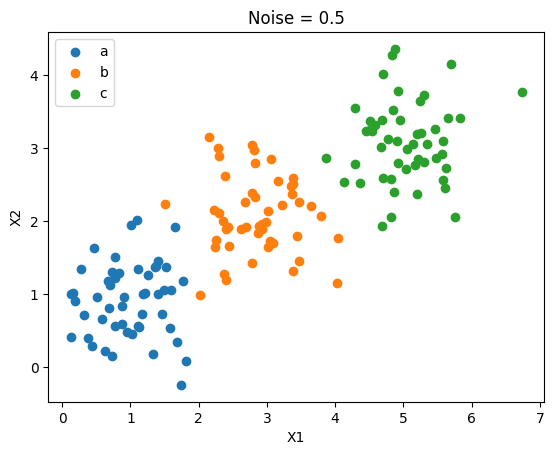

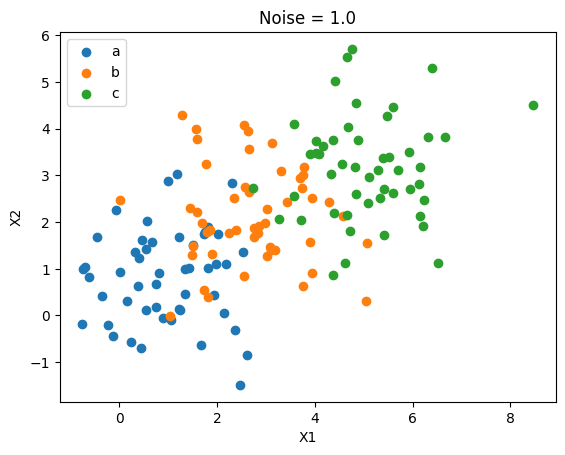

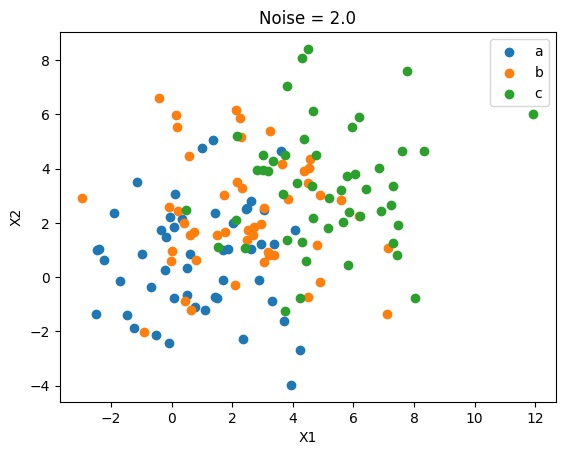

In [68]:
#Question 1.2


import matplotlib.pyplot as plt

for df, noise in zip([df0_125, df0_25, df0_5, df1_0, df2_0],
 [0.125, 0.25, 0.5, 1.0, 2.0]):
    for group in ['a', 'b', 'c']:
        data = df[df['group'] == group]
        plt.scatter(data['x1'], data['x2'], label=group)

    plt.title(f"Noise = {noise}")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.legend()
    plt.show()


#As the noise increases from 0.125 to 2.0, the clusters become more spread out and overlap more.
#At low noise levels the clusters are clearly separated, but at higher noise levels its harder to distinguish between the groups without the labelling.

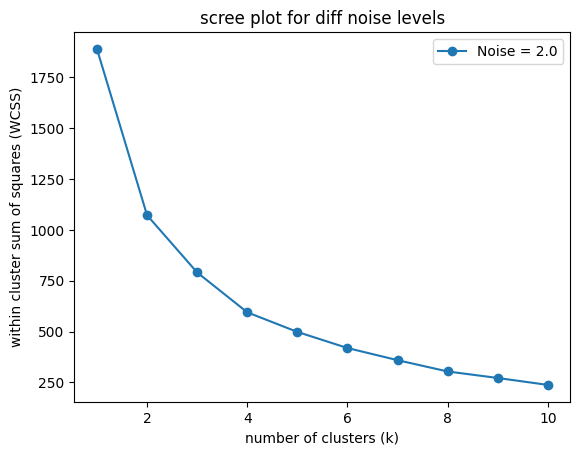

In [70]:
# Question 1.3
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(datasets, noises):
  X = df[['x1', 'x2']]
  wcss = []

for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o', label=f'Noise = {noise}')

plt.xlabel('number of clusters (k)')
plt.ylabel('within cluster sum of squares (WCSS)')
plt.title('scree plot for diff noise levels')
plt.legend()
plt.show()

#As noise increases, the wcss values increase because the points are more spread out.
#At low noise levels, the scree plot has a clearer elbow shape, suggesting three clusters.
#As noise increases, the elbow becomes less distinct, which makes it harder to determine the best value of.

In [ ]:
# Question 1.4
#The elbow method looks for the point where adding more clusters stops making a big difference in reducing the wcss.
#For this graph/data, the elbow is around k=3 since the data was created with three groups.
#Adding clusters before k=3 reduced the wcss, but adding more clusters after that only reduced it a little.
#As the noise increases, the elbow becomes less clear because the groups overlap more, making it harder to choose the best k.

In [25]:
# Question 2.1


import pandas as pd

df = pd.read_csv('SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020]
df = df.dropna()

df = df.drop(columns=['index', 'Year', 'Country'])

df.head()

#Further cleaning is needed. I would remove the country name, year, and index columns because they aren't useful for clustering.
#I would also make sure the military spending variables are numeric and standardize them before clustering so that variables with larger values don't have more influence just because of their scale.

df.shape[0]

148

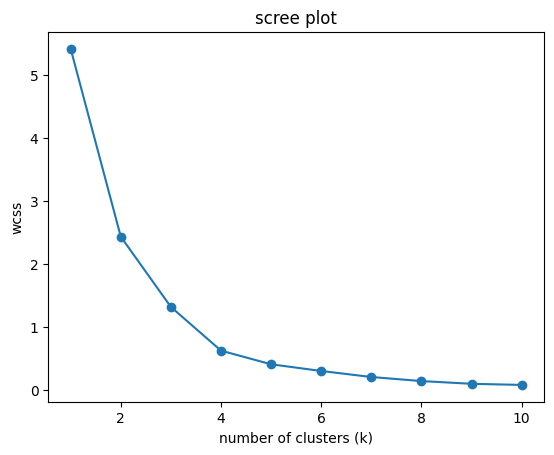

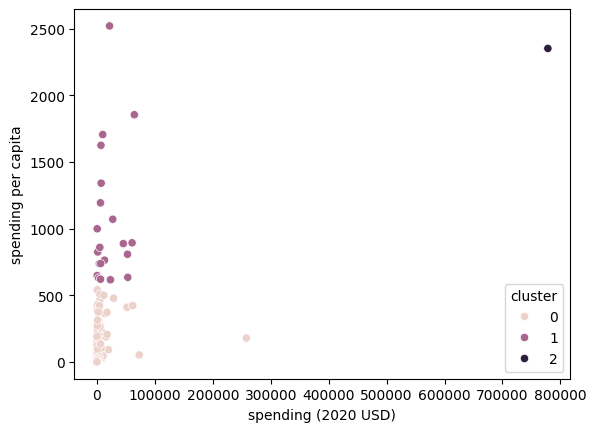

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     126.0    5943.346303  24858.961064       8.622460   
1                      21.0   19975.991473  21749.736747     405.790494   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           162.761743     580.758315    3225.333414  257973.429834   
1          4980.428135    7269.880030   27300.894701   64558.400000   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

In [71]:
#Question 2.2

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy()

X = df[['Spending (2020 USD)', 'Spending per Capita']]
X_scaled = MinMaxScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X_scaled)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('wcss')
plt.title('scree plot')
plt.show()

k = 3

df['cluster'] = KMeans(n_clusters=k, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df, x='Spending (2020 USD)',y='Spending per Capita', hue='cluster')
plt.xlabel('spending (2020 USD)')
plt.ylabel('spending per capita')
plt.show()

print(df.groupby('cluster')[['Spending (2020 USD)','Spending per Capita']].describe())

print(df[df['Country'] == 'United States of America'][['Country','Spending (2020 USD)','Spending per Capita','cluster']])


#The scree plot shows an elbow around k=3/k=4, so I chose k=3.
#The scatterplot shows that most countries are in cluster 0, which has lower military spending and spending per capita.
#Cluster 1 has fewer countries with higher spending per capita, and cluster 2 contains only one country with much higher total military spending than the others.
#The United States is probably in cluster 2 because it has very high military spending.
#The clusters show that countries with similar military spending patterns tend to be grouped together, while countries with high/different spending patterns can form their own cluster.


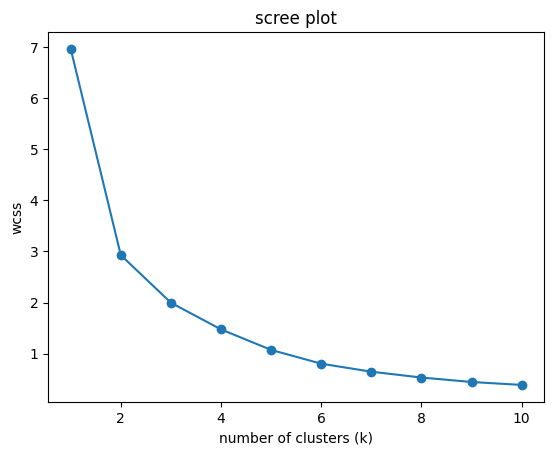

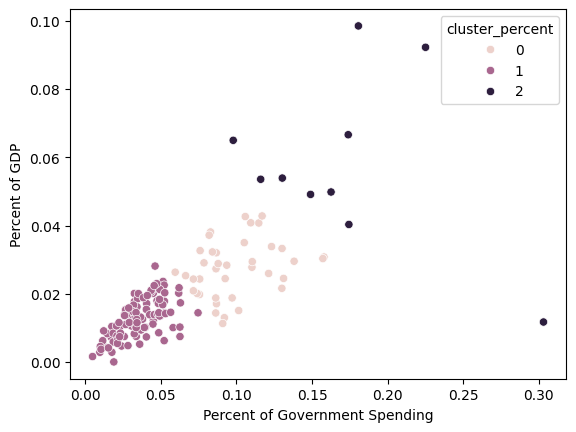

In [72]:
# Question 2.3

import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['Percent of Government Spending', 'Percent of GDP']

X = df[cols].apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan).dropna()

df_percent = df.loc[X.index].copy()

X_scaled = MinMaxScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X_scaled)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('wcss')
plt.title('scree plot')
plt.show()

df_percent['cluster_percent'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_percent,
                x=cols[0],
                y=cols[1],
                hue='cluster_percent')
plt.show()

#Compared to part 2, where I used total military spending and spending per capita, these are focused more on military spending as a percentage of government spending and GDP.
#The scree plot shows that 4 clusters could be a good choice because the curve starts to level off after that, but I used 3 clusters to keep it consistent with part 2.
#The scatterplot shows that most countries have low percentages for both variables, while a few countries have higher values/outliers.
#Compared to part 2, the variables show how much of a country's government spending and economy goes toward the military instead of the total amount of money spent.
#This creates a different distribution of countries.

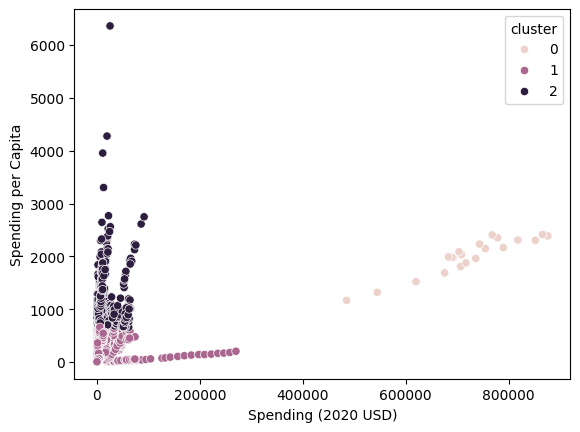

In [52]:
# Question 2.4

X = df[['Spending (2020 USD)', 'Spending per Capita','Percent of Government Spending', 'Percent of GDP']].dropna()

X_scaled = MinMaxScaler().fit_transform(X)

df_all = df.loc[X.index].copy()
df_all['cluster'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_all, x='Spending (2020 USD)',y='Spending per Capita', hue='cluster')

plt.show()

#Using all four variables combines the info from the last two parts because it takes the amount countries spend on their military and the percent of government spending and GDP.
#Most countries are grouped closer to the lower spending values, and some countries have higher spending per capita or a lot higher total military spending.
#Compared to the previous parts, using all four variables has more information when grouping countries and this can lead to different cluster assignments.
#Overall, I think this would give a more complete comparison of military spending patterns.

In [ ]:
#The K-means clustering algorithm found some useful patterns in military spending.
#It showed me that most countries have relatively low total military spending, while a smaller group spends much more.
#It also showed that countries can differ in spending per capita and in the percent of government spending and GDP devoted to the military.
#Clustering helped identify similarities and differences between countries, although it didn't not explain why the differences exist.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [1]:
# Your Phase 1 solution to the problem goes here.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [2]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]